## 1. Đọc dữ liệu và kiểm tra cấu trúc

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc dữ liệu: sửa đường dẫn theo vị trí file của cậu
df = pd.read_csv("./data/HousingPrices-Amsterdam-August-2021.csv")

# Hiển thị 5 dòng đầu
display(df.head())

# Kiểm tra cấu trúc dữ liệu
print("Kích thước dữ liệu:", df.shape)
print("\nTên các cột:")
print(df.columns.tolist())

print("\nThông tin dữ liệu:")
df.info()

print("\nSố lượng giá trị thiếu:")
print(df.isnull().sum())

,Unnamed: 0,Address,Zip,Price,Area,Room,Lon,Lat
0,1,"Blasiusstraat 8 2, Amsterdam",1091 CR,685000.0,64,3,4.907736,52.356157
1,2,"Kromme Leimuidenstraat 13 H, Amsterdam",1059 EL,475000.0,60,3,4.850476,52.348586
2,3,"Zaaiersweg 11 A, Amsterdam",1097 SM,850000.0,109,4,4.944774,52.343782
3,4,"Tenerifestraat 40, Amsterdam",1060 TH,580000.0,128,6,4.789928,52.343712
4,5,"Winterjanpad 21, Amsterdam",1036 KN,720000.0,138,5,4.902503,52.410538


Kích thước dữ liệu: (924, 8)

Tên các cột:
['Unnamed: 0', 'Address', 'Zip', 'Price', 'Area', 'Room', 'Lon', 'Lat']

Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 924 entries, 0 to 923
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  924 non-null    int64  
 1   Address     924 non-null    object 
 2   Zip         924 non-null    object 
 3   Price       920 non-null    float64
 4   Area        924 non-null    int64  
 5   Room        924 non-null    int64  
 6   Lon         924 non-null    float64
 7   Lat         924 non-null    float64
dtypes: float64(3), int64(3), object(2)
memory usage: 57.9+ KB

Số lượng giá trị thiếu:
Unnamed: 0    0
Address       0
Zip           0
Price         4
Area          0
Room          0
Lon           0
Lat           0
dtype: int64


#### 2. Thống kê mô tả các biến định lượng

In [3]:
# Chọn các cột có kiểu dữ liệu số
numeric_df = df.select_dtypes(include="number")

# Thống kê mô tả
display(numeric_df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,924.0,462.500000,266.880123,1.000000,231.750000,462.500000,693.250000,9.240000e+02
Price,920.0,622065.419565,538994.175364,175000.000000,350000.000000,467000.000000,700000.000000,5.950000e+06
Area,924.0,95.952381,57.447436,21.000000,60.750000,83.000000,113.000000,6.230000e+02
Room,924.0,3.571429,1.592332,1.000000,3.000000,3.000000,4.000000,1.400000e+01
Lon,924.0,4.888605,0.053140,4.644819,4.855834,4.886818,4.922337,5.029122e+00
Lat,924.0,52.363326,0.024028,52.291519,52.352077,52.364631,52.377598,5.242381e+01


## 3. Phân tích biến giá nhà

In [4]:
# Thay "Price" bằng tên cột giá nhà thực tế
price = pd.to_numeric(df["Price"], errors="coerce").dropna()

print("Số lượng:", price.count())
print("Trung bình:", price.mean())
print("Trung vị:", price.median())
print("Độ lệch chuẩn:", price.std())
print("Nhỏ nhất:", price.min())
print("Lớn nhất:", price.max())

print("\nCác tứ phân vị:")
print(price.quantile([0.25, 0.5, 0.75]))

Số lượng: 920
Trung bình: 622065.4195652173
Trung vị: 467000.0
Độ lệch chuẩn: 538994.1753643245
Nhỏ nhất: 175000.0
Lớn nhất: 5950000.0

Các tứ phân vị:
0.25    350000.0
0.50    467000.0
0.75    700000.0
Name: Price, dtype: float64


## 4. Vẽ biểu đồ Histogram và Boxplot

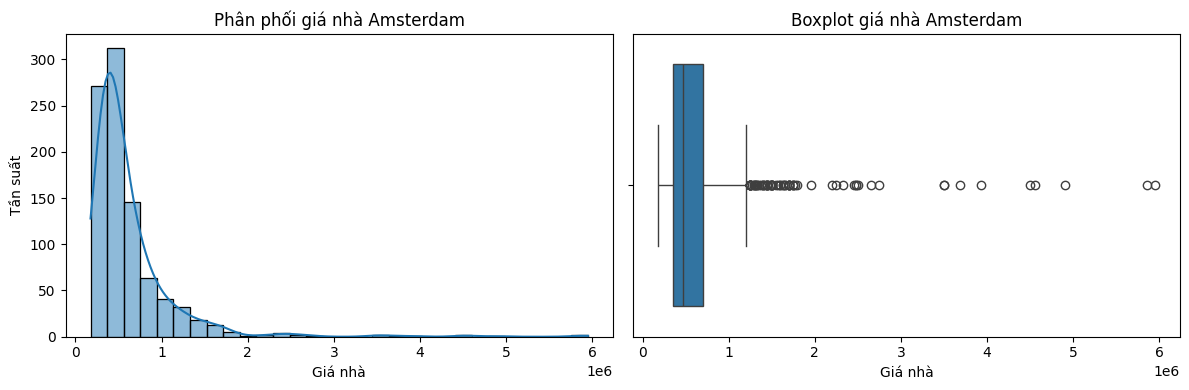

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram: phân phối giá nhà
sns.histplot(price, bins=30, kde=True, ax=axes[0])
axes[0].set_title("Phân phối giá nhà Amsterdam")
axes[0].set_xlabel("Giá nhà")
axes[0].set_ylabel("Tần suất")

# Boxplot: độ phân tán và ngoại lệ
sns.boxplot(x=price, ax=axes[1])
axes[1].set_title("Boxplot giá nhà Amsterdam")
axes[1].set_xlabel("Giá nhà")

plt.tight_layout()
plt.show()

## 5. Phân tích biến phân loại

In [6]:
# Lấy các cột phân loại
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(10))


--- Address ---
Address
Huidekoperstraat 24 F, Amsterdam             2
Uilengouw 2, Amsterdam                       2
Nieuwevaartweg, Amsterdam                    2
Quashibastraat, Amsterdam                    2
Ringdijk, Amsterdam                          2
Blasiusstraat 50 II, Amsterdam               1
Suikerpeerpad 39, Amsterdam                  1
Paramaribostraat 122 3, Amsterdam            1
Burgemeester Hogguerstraat 273, Amsterdam    1
Anna Blamansingel 274 VII, Amsterdam         1
Name: count, dtype: int64

--- Zip ---
Zip
1075 XR    5
1017 KP    4
1095 MD    3
1060 RZ    3
1087 VS    3
1011 AW    3
1068 WT    3
1077 KG    3
1060 SC    3
1087 KH    3
Name: count, dtype: int64
